
# MNIST Dataset: Data Extraction and Preprocessing

## Project Overview
This project focuses on acquiring the MNIST handwritten digit dataset
from the provided URL, extracting its contents, performing exploratory
data analysis, validating data quality, and preparing the images for
subsequent machine learning tasks.

## Objectives
- Load the dataset directly from the provided source.
- Understand the structure and characteristics of the data.
- Inspect image dimensions, labels, pixel values, and data types.
- Apply appropriate preprocessing techniques.
- Validate the processed data for correctness and consistency.

## Dataset Source
https://storage.googleapis.com/tensorflow/tf-keras-datasets/mnist.npz

## Scope
This project covers data preparation and quality validation.
Model training and prediction are outside the current scope.


In [1]:

# ============================================================
# 1. ENVIRONMENT SETUP AND LIBRARY IMPORTS
# ============================================================

import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

# Reproducibility and runtime information
print("Environment initialized successfully.")
print(f"Python environment: Google Colab")
print(f"NumPy version: {np.__version__}")
print(f"TensorFlow version: {tf.__version__}")
print(f"Working directory: {os.getcwd()}")


Environment initialized successfully.
Python environment: Google Colab
NumPy version: 2.1.3
TensorFlow version: 2.21.0
Working directory: /content


In [2]:

# ============================================================
# 2. DATASET ACQUISITION
# ============================================================

# Official dataset URL provided by the instructor
DATASET_URL = (
    "https://storage.googleapis.com/"
    "tensorflow/tf-keras-datasets/mnist.npz"
)

# Download the dataset to the Colab environment
dataset_path = tf.keras.utils.get_file(
    fname="mnist.npz",
    origin=DATASET_URL
)

print("Dataset download completed.")
print("Dataset path:", dataset_path)


11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Dataset download completed.
Dataset path: /root/.keras/datasets/mnist.npz


In [3]:

# ============================================================
# 3. DOWNLOAD VALIDATION
# ============================================================

if not os.path.isfile(dataset_path):
    raise FileNotFoundError("Dataset file was not found.")

file_size_bytes = os.path.getsize(dataset_path)
file_size_mb = file_size_bytes / (1024 * 1024)

if file_size_bytes == 0:
    raise ValueError("Downloaded dataset is empty.")

print("File verification passed.")
print(f"File size: {file_size_mb:.2f} MB")
print(f"File exists: {os.path.isfile(dataset_path)}")


File verification passed.
File size: 10.96 MB
File exists: True


In [4]:

# ============================================================
# 4. ARCHIVE INSPECTION
# ============================================================

if not dataset_path.endswith(".npz"):
    raise ValueError("Expected an NPZ archive.")

with np.load(dataset_path, allow_pickle=False) as archive:
    available_arrays = archive.files

print("Archive opened successfully.")
print("Arrays available in the archive:", available_arrays)

expected_arrays = {
    "x_train", "y_train", "x_test", "y_test"
}

if set(available_arrays) != expected_arrays:
    raise ValueError(
        f"Unexpected dataset structure: {available_arrays}"
    )

print("Archive structure validated successfully.")


Archive opened successfully.
Arrays available in the archive: ['x_test', 'x_train', 'y_train', 'y_test']
Archive structure validated successfully.



# ============================================================
# 4. ARCHIVE INSPECTION
# ============================================================

if not dataset_path.endswith(".npz"):
    raise ValueError("Expected an NPZ archive.")

with np.load(dataset_path, allow_pickle=False) as archive:
    available_arrays = archive.files

print("Archive opened successfully.")
print("Arrays available in the archive:", available_arrays)

expected_arrays = {
    "x_train", "y_train", "x_test", "y_test"
}

if set(available_arrays) != expected_arrays:
    raise ValueError(
        f"Unexpected dataset structure: {available_arrays}"
    )

print("Archive structure validated successfully.")


In [5]:

# Load the training and testing data
with np.load(dataset_path, allow_pickle=False) as data:
    x_train = data["x_train"]
    y_train = data["y_train"]
    x_test = data["x_test"]
    y_test = data["y_test"]

print("Training images:", x_train.shape)
print("Training labels:", y_train.shape)
print("Testing images:", x_test.shape)
print("Testing labels:", y_test.shape)


Training images: (60000, 28, 28)
Training labels: (60000,)
Testing images: (10000, 28, 28)
Testing labels: (10000,)



## 4. Initial Data Exploration

I checked the data types, pixel intensity range, and available digit
labels to understand the dataset before applying preprocessing.


In [6]:

print("Image data type:", x_train.dtype)
print("Label data type:", y_train.dtype)

print("Minimum pixel value:", x_train.min())
print("Maximum pixel value:", x_train.max())

print("Unique labels:", np.unique(y_train))


Image data type: uint8
Label data type: uint8
Minimum pixel value: 0
Maximum pixel value: 255
Unique labels: [0 1 2 3 4 5 6 7 8 9]


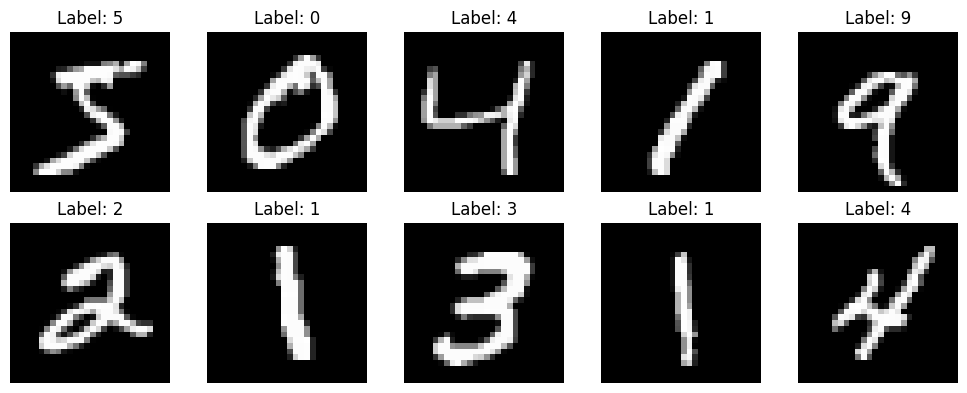

In [7]:

plt.figure(figsize=(10, 4))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap="gray")
    plt.title(f"Label: {y_train[i]}")
    plt.axis("off")

plt.tight_layout()
plt.show()


In [8]:

# Check for missing or invalid values
print("Missing values in training images:", np.isnan(x_train).sum())
print("Missing values in testing images:", np.isnan(x_test).sum())

print("Minimum training label:", y_train.min())
print("Maximum training label:", y_train.max())

print("Training image dimensions:", x_train.shape[1:])
print("Testing image dimensions:", x_test.shape[1:])

# Validate the expected structure
assert x_train.shape == (60000, 28, 28)
assert x_test.shape == (10000, 28, 28)
assert len(x_train) == len(y_train)
assert len(x_test) == len(y_test)
assert np.isin(y_train, np.arange(10)).all()
assert np.isin(y_test, np.arange(10)).all()

print("Dataset structure and labels validated successfully.")


Missing values in training images: 0
Missing values in testing images: 0
Minimum training label: 0
Maximum training label: 9
Training image dimensions: (28, 28)
Testing image dimensions: (28, 28)
Dataset structure and labels validated successfully.



## 5. Data Preprocessing

The original pixel values range from 0 to 255. I will convert the
image data to floating-point values and normalize the pixels to a
range between 0 and 1.

This makes the input values more suitable for common machine learning
workflows while keeping the original training and testing split intact.


In [9]:

# Convert pixel values to floating point and normalize
x_train = x_train.astype(np.float32) / 255.0
x_test = x_test.astype(np.float32) / 255.0

print("Training pixel range:", x_train.min(), "to", x_train.max())
print("Testing pixel range:", x_test.min(), "to", x_test.max())

print("Training data type:", x_train.dtype)
print("Testing data type:", x_test.dtype)


Training pixel range: 0.0 to 1.0
Testing pixel range: 0.0 to 1.0
Training data type: float32
Testing data type: float32



## 6. Preparing the Processed Data

After normalization, I will prepare a flattened representation of the
images for use with a fully connected neural network.

Each 28 × 28 image will be converted into a one-dimensional array
containing 784 pixel values. The original image dimensions will be
preserved in the normalized image arrays.


In [10]:

# Flatten images from 28 x 28 pixels into 784 features
x_train_flat = x_train.reshape(x_train.shape[0], -1)
x_test_flat = x_test.reshape(x_test.shape[0], -1)

print("Processed training data:", x_train_flat.shape)
print("Processed testing data:", x_test_flat.shape)
print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)


Processed training data: (60000, 784)
Processed testing data: (10000, 784)
Training labels: (60000,)
Testing labels: (10000,)


In [11]:

# Final validation of the processed dataset

assert x_train_flat.shape == (60000, 784)
assert x_test_flat.shape == (10000, 784)

assert x_train_flat.dtype == np.float32
assert x_test_flat.dtype == np.float32

assert np.isfinite(x_train_flat).all()
assert np.isfinite(x_test_flat).all()

assert x_train_flat.min() >= 0.0
assert x_train_flat.max() <= 1.0
assert x_test_flat.min() >= 0.0
assert x_test_flat.max() <= 1.0

assert len(x_train_flat) == len(y_train)
assert len(x_test_flat) == len(y_test)

print("Final validation passed.")
print("Training samples:", x_train_flat.shape[0])
print("Testing samples:", x_test_flat.shape[0])
print("Features per image:", x_train_flat.shape[1])
print("Pixel range: 0 to 1")
print("Data is ready for subsequent machine learning tasks.")


Final validation passed.
Training samples: 60000
Testing samples: 10000
Features per image: 784
Pixel range: 0 to 1
Data is ready for subsequent machine learning tasks.


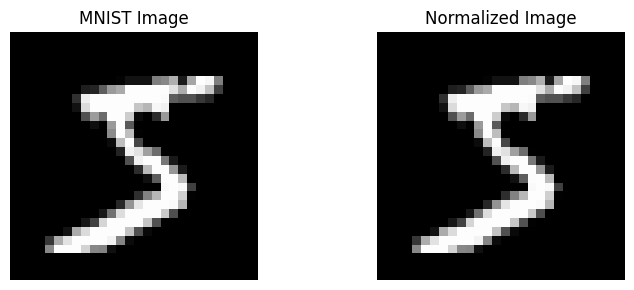

Digit label: 5
Number of flattened features: 784


In [12]:

# Compare the original pixel scale with normalized pixel values

index = 0

fig, axes = plt.subplots(1, 2, figsize=(8, 3))

axes[0].imshow(
    (x_train[index] * 255).astype(np.uint8),
    cmap="gray"
)
axes[0].set_title("MNIST Image")
axes[0].axis("off")

axes[1].imshow(x_train[index], cmap="gray", vmin=0, vmax=1)
axes[1].set_title("Normalized Image")
axes[1].axis("off")

plt.tight_layout()
plt.show()

print("Digit label:", y_train[index])
print("Number of flattened features:", x_train_flat[index].size)



## 7. Conclusion

In this practical, I downloaded the MNIST dataset from the provided
URL and extracted the training and testing arrays. I explored the
dataset structure, inspected sample images and labels, checked data
quality, and normalized the image pixel values.

I also prepared flattened versions of the images containing 784
features per sample and verified the dimensions, data types, and
pixel ranges.

The dataset is now prepared for further machine learning experiments.
Model training and prediction were not included in this practical.
